<h1>Utkarsh 202501100300280 CSE AI D</h1>
<h1>Case Study 4</h1>
E-commerce customer segmentation - Apply K-means and DBSCAN to an RFM(Recency, Frequency, Monetary) dataset from an online retailer. Reduce dimensions with PCA, visualize segments with t-SNE, and derive actionable marketing personas from each cluster.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [6]:
df = pd.read_csv('/content/E-commerce Customer dataset_CS4.csv')
print("Dataset uploaded")

Dataset uploaded


In [7]:
df.shape

(541909, 8)

In [8]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [9]:
print(df.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [11]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [12]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [13]:
df = df.dropna(subset=['CustomerID'])

# Remove cancelled transactions
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

#  keep only positive quantities and prices
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]

# converting the columns to correct data types
df['CustomerID'] = df['CustomerID'].astype(int)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

df.head()
df.shape
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [14]:
df["TotalAmount"] = df['Quantity']*df['UnitPrice']

# Set the reference date to one day after the last transaction
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency = ("InvoiceDate", lambda x : (reference_date -x.max()).days),
    Frequency = ("InvoiceNo", "nunique"),
    Monetary  = ("TotalAmount", "sum")
).reset_index()

print(rfm.head())

print("\nRFM dataset shape : ", rfm.shape)

   CustomerID  Recency  Frequency  Monetary
0       12346      326          1  77183.60
1       12347        2          7   4310.00
2       12348       75          4   1797.24
3       12349       19          1   1757.55
4       12350      310          1    334.40

RFM dataset shape :  (4338, 4)


In [15]:
print(rfm[['Recency', 'Frequency', 'Monetary']].describe())

print("/nMissing values in rfm :", rfm.isnull().sum())


           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2054.266460
std     100.014169     7.697998    8989.230441
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     307.415000
50%      51.000000     2.000000     674.485000
75%     142.000000     5.000000    1661.740000
max     374.000000   209.000000  280206.020000
/nMissing values in rfm : CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64


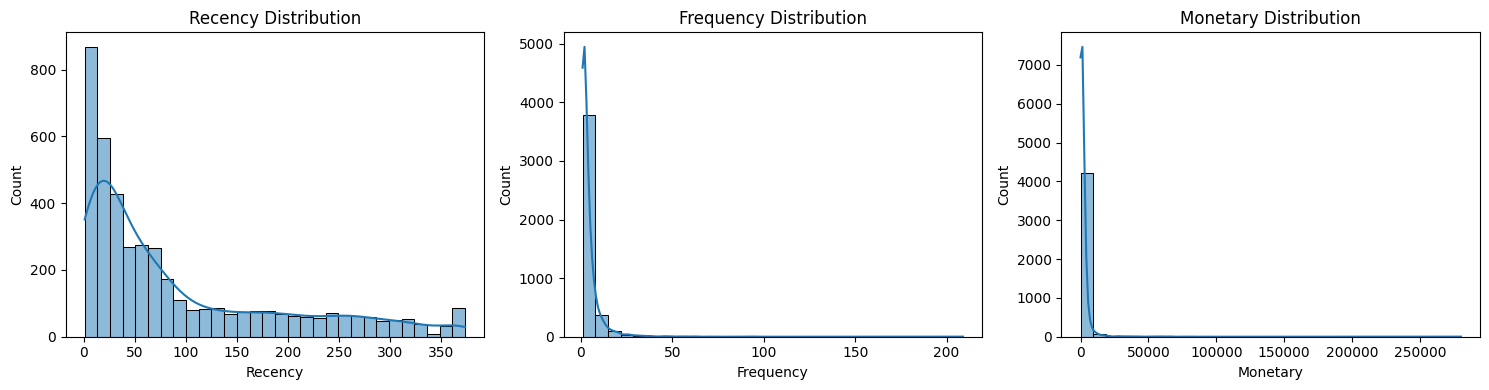

In [16]:
import seaborn as sns

plt.figure(figsize=(15,4))
plt.subplot(1,3,1)
sns.histplot(rfm['Recency'], bins = 30, kde = True)
plt.title("Recency Distribution")


plt.subplot(1, 3, 2)
sns.histplot(rfm["Frequency"], bins=30, kde=True)
plt.title("Frequency Distribution")

plt.subplot(1, 3, 3)
sns.histplot(rfm["Monetary"], bins=30, kde=True)
plt.title("Monetary Distribution")

plt.tight_layout()
plt.show()

In [17]:
X = rfm[["Recency", "Frequency", "Monetary"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standardized Data: ")
print(X_scaled[:5])

Standardized Data: 
[[ 2.33457414 -0.4250965   8.35866818]
 [-0.90534032  0.3544168   0.25096626]
 [-0.17535959 -0.03533985 -0.02859601]
 [-0.73534481 -0.4250965  -0.0330118 ]
 [ 2.17457836 -0.4250965  -0.19134727]]


In [18]:
kmeans = KMeans(n_clusters=4, random_state = 42, n_init=10)

rfm["Cluster"] = kmeans.fit_predict(X_scaled)
print(rfm.head())

print("/nCount of customers in each cluster : ")
print(rfm["Cluster"].value_counts().sort_index())

   CustomerID  Recency  Frequency  Monetary  Cluster
0       12346      326          1  77183.60        3
1       12347        2          7   4310.00        0
2       12348       75          4   1797.24        0
3       12349       19          1   1757.55        0
4       12350      310          1    334.40        1
/nCount of customers in each cluster : 
Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


In [19]:
# calculation of average RFM values form each cluster
cluster_analysis = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(2)
print(cluster_analysis)

         Recency  Frequency   Monetary
Cluster                               
0          43.70       3.68    1359.05
1         248.08       1.55     480.62
2           7.38      82.54  127338.31
3          15.50      22.33   12709.09


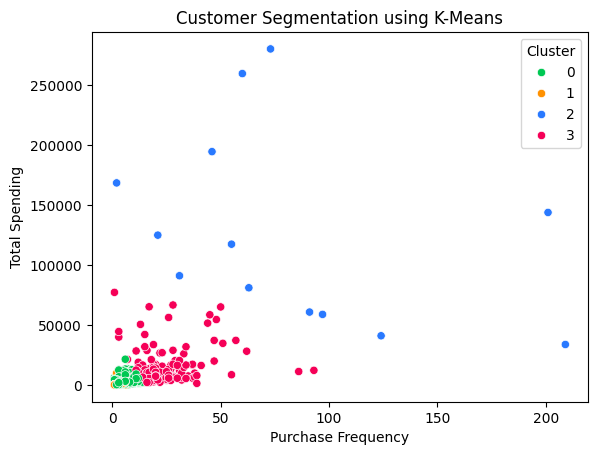

In [20]:
bright_colors = ["#00C853", "#FF9100", "#2979FF", "#F50057"]

sns.scatterplot(
    data = rfm,
    x = "Frequency",
    y="Monetary",
    hue= "Cluster",
    palette = bright_colors
)
plt.title("Customer Segmentation using K-Means")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")
plt.show()

In [21]:
# Calculate average RFM values and customer count for each cluster
summary = rfm.groupby("Cluster").agg(
    CustomerCount=("CustomerID", "count"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean")
).round(2)

print(summary)

         CustomerCount  AvgRecency  AvgFrequency  AvgMonetary
Cluster                                                      
0                 3054       43.70          3.68      1359.05
1                 1067      248.08          1.55       480.62
2                   13        7.38         82.54    127338.31
3                  204       15.50         22.33     12709.09


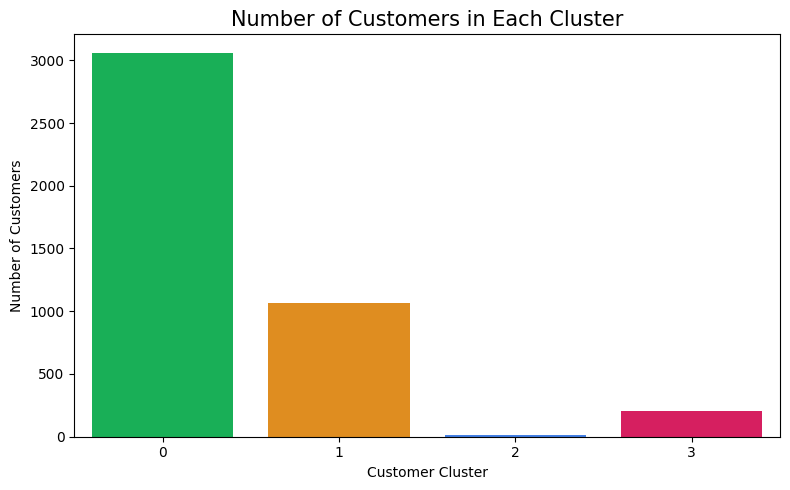

In [22]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8,5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values,
    hue=cluster_counts.index,
    palette=["#00C853", "#FF9100", "#2979FF", "#F50057"],
    legend=False
)

plt.title("Number of Customers in Each Cluster", fontsize=15)
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()

<h1>DBSCAN Algorithm </h1>

In [23]:
dbs = DBSCAN(eps = 0.5, min_samples = 5)

rfm["DBS_Cluster"] = dbs.fit_predict(X_scaled)

print(rfm.head())

print("/nDBSCAN Cluster counts:")
print(rfm["DBS_Cluster"].value_counts().sort_index())

   CustomerID  Recency  Frequency  Monetary  Cluster  DBS_Cluster
0       12346      326          1  77183.60        3           -1
1       12347        2          7   4310.00        0            0
2       12348       75          4   1797.24        0            0
3       12349       19          1   1757.55        0            0
4       12350      310          1    334.40        1            0
/nDBSCAN Cluster counts:
DBS_Cluster
-1      54
 0    4284
Name: count, dtype: int64


In [24]:
from sklearn.cluster import DBSCAN
import numpy as np

for eps_value in [0.3, 0.5, 0.7, 1.0]:
    dbscan = DBSCAN(eps=eps_value, min_samples=5)
    labels = dbscan.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)

    print(f"eps = {eps_value}")
    print(f"Number of clusters: {n_clusters}")
    print(f"Number of noise points: {n_noise}")
    print("-" * 30)

eps = 0.3
Number of clusters: 2
Number of noise points: 107
------------------------------
eps = 0.5
Number of clusters: 1
Number of noise points: 54
------------------------------
eps = 0.7
Number of clusters: 1
Number of noise points: 45
------------------------------
eps = 1.0
Number of clusters: 1
Number of noise points: 33
------------------------------


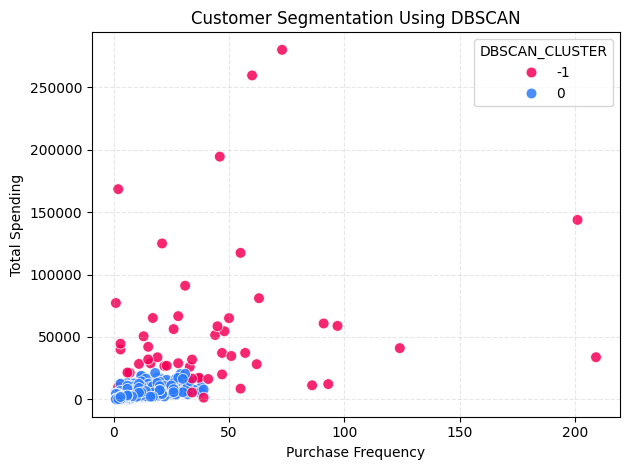

In [25]:
sns.scatterplot(
    data = rfm,
    x="Frequency",
    y="Monetary",
    hue="DBS_Cluster",
    palette={-1: "#F50057", 0: "#2979FF"},
    s=60,
    alpha=0.85
)


plt.title("Customer Segmentation Using DBSCAN")
plt.xlabel("Purchase Frequency")
plt.ylabel("Total Spending")

plt.legend(title = "DBSCAN_CLUSTER")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

<h1>Applying PCA</h1>

In [26]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:", pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.55502102 0.30249315]
Total variance explained: 0.8575141741259507


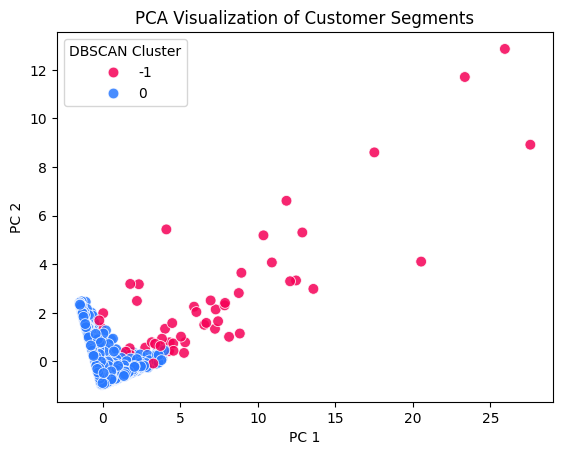

In [27]:
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm["DBS_Cluster"],
    palette={-1: "#F50057", 0: "#2979FF"},
    s=60,
    alpha=0.85
)

plt.title("PCA Visualization of Customer Segments")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(title = "DBSCAN Cluster")
plt.show()

<h1>Applying t-SNE</h1>

<Axes: >

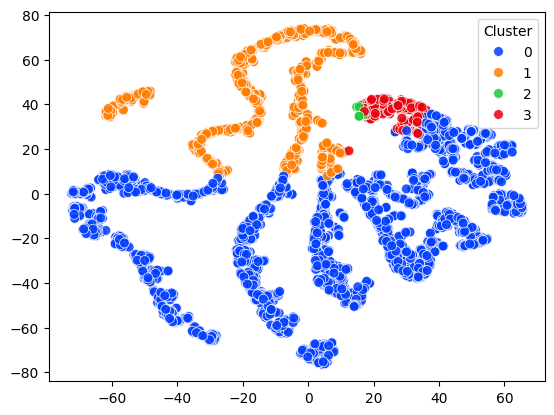

In [28]:
tsne = TSNE(
    n_components = 2,
    random_state = 42,
    perplexity = 30
    )
X_tsne = tsne.fit_transform(X_scaled)

# Visualize K-Means clusters
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=rfm["Cluster"],
    palette="bright",
    s=50,
    alpha=0.85
)

<h1>Comparing the results of both K-Means and DBSCAN</h1>

In [29]:
print("K-Means cluster counts:")
print(rfm["Cluster"].value_counts().sort_index())
print("/nDBSCAN Cluster counts:")
print(rfm["DBS_Cluster"].value_counts().sort_index())

K-Means cluster counts:
Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64
/nDBSCAN Cluster counts:
DBS_Cluster
-1      54
 0    4284
Name: count, dtype: int64


In [30]:
recency_median = rfm["Recency"].median()
frequency_median = rfm["Frequency"].median()

def classify_customer(row):
    recency = row["Recency"]
    frequency = row["Frequency"]

    if (recency < recency_median
            and frequency > frequency_median):
        return "Loyal or active customers"

    elif recency > recency_median:
        return "Inactive or at-risk customers"

    else:
        return "Occasional customers"

rfm["Persona"] = rfm.apply(classify_customer, axis=1)

print(rfm[["CustomerID", "Recency", "Frequency", "Persona"]].head(10))

print("\nCustomer Persona Distribution:")
print(rfm["Persona"].value_counts())

   CustomerID  Recency  Frequency                        Persona
0       12346      326          1  Inactive or at-risk customers
1       12347        2          7      Loyal or active customers
2       12348       75          4  Inactive or at-risk customers
3       12349       19          1           Occasional customers
4       12350      310          1  Inactive or at-risk customers
5       12352       36          8      Loyal or active customers
6       12353      204          1  Inactive or at-risk customers
7       12354      232          1  Inactive or at-risk customers
8       12355      214          1  Inactive or at-risk customers
9       12356       23          3      Loyal or active customers

Customer Persona Distribution:
Persona
Inactive or at-risk customers    2150
Loyal or active customers        1438
Occasional customers              750
Name: count, dtype: int64
